# Batch sharing: who reuses what

When many questions are asked about the same program, how much simulation is really
needed? This notebook asks 16 questions about an 8-qubit program and compares the
planner's strategies: what each one simulates, what that costs, and where sharing
starts to pay off as the program grows.

In [1]:
import os

# One native thread per library, so timings compare algorithms rather than core counts.
# This has to happen before Qulacs is imported.
for key in ("QULACS_NUM_THREADS", "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[key] = "1"

import math

import matplotlib.pyplot as plt

from lazyqc import Program, plan_all
from nbtools import compare, table, timed

COLORS = {"full": "#E67E22", "separate": "#8E44AD", "grouped": "#007D84", "auto": "#5FB3B8"}


def tidy(ax):
    """Light styling shared by the charts below."""
    ax.grid(alpha=0.3)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

## The program: independent pairs

The building block from notebook 01, repeated: pair $j$ gets its own angle, and we
ask four questions about each pair ($Z_a$, $Z_b$, $Z_aZ_b$ and $X_aX_b$).

In [2]:
def pairs_program(pairs):
    """`pairs` independent entangled pairs and four questions about each one."""
    program = Program(2 * pairs)
    for j in range(pairs):
        a, b = 2 * j, 2 * j + 1
        program = program.ry(a, (j + 1) * math.pi / (2 * pairs + 1)).cx(a, b)
    requests = []
    for j in range(pairs):
        a, b = 2 * j, 2 * j + 1
        for obs in ({a: "Z"}, {b: "Z"}, {a: "Z", b: "Z"}, {a: "X", b: "X"}):
            requests.append(program.expectation(obs))
    return program, requests


program, requests = pairs_program(4)
print(f"{program.n_qubits} qubits, {len(requests)} questions")

8 qubits, 16 questions


## Four strategies, one batch

- **full**: one 8-qubit state, reused for every question;
- **separate**: one 2-qubit simulation per question, no reuse at all;
- **grouped**: one simulation per distinct cone; the four questions about a pair
  share its cone, so there are 4 simulations;
- **auto**: score the three candidates above and keep the cheapest.

We force each strategy in turn and put what it simulated next to the measured time
(median of five runs, planning included).

| strategy | state evolutions | largest state (qubits) | state memory (bytes) | median time (ms) |
|---|---|---|---|---|
| full | 1 | 8 | 4096 | 0.199 |
| separate | 16 | 2 | 64 | 0.419 |
| grouped | 4 | 2 | 64 | 0.298 |
| auto | 4 | 2 | 64 | 0.239 |

auto chose grouped; the fastest run here was full


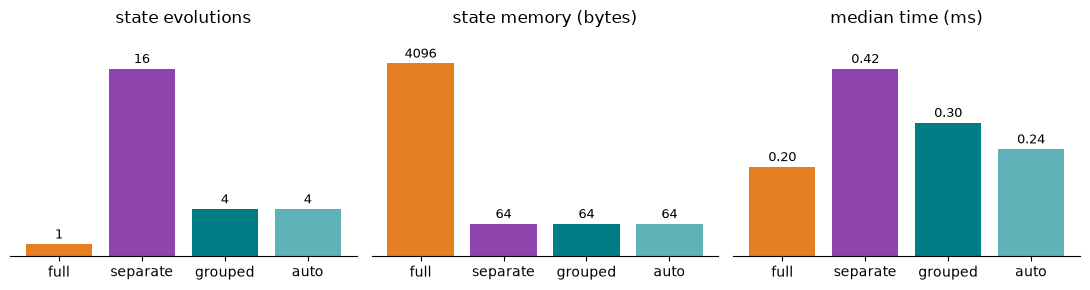

In [3]:
rows = []
for strategy in ("full", "separate", "grouped", "auto"):
    result, ms = timed(lambda s=strategy: plan_all(requests, strategy=s).collect())
    stats = result.stats
    rows.append((strategy, stats.evolutions, stats.max_state_qubits, stats.estimated_state_bytes, ms))
table(rows, ["strategy", "state evolutions", "largest state (qubits)", "state memory (bytes)", "median time (ms)"])

chosen = plan_all(requests).explain()["selected_candidate"]
fastest = min(rows, key=lambda row: row[-1])[0]
print(f"auto chose {chosen}; the fastest run here was {fastest}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3))
panels = (("state evolutions", 1, "{:d}"), ("state memory (bytes)", 3, "{:d}"), ("median time (ms)", 4, "{:.2f}"))
for ax, (title, column, fmt) in zip(axes, panels):
    bars = ax.bar([r[0] for r in rows], [r[column] for r in rows], color=[COLORS[r[0]] for r in rows])
    ax.bar_label(bars, labels=[fmt.format(r[column]) for r in rows], padding=2, fontsize=9)
    ax.set_title(title)
    ax.margins(y=0.2)
    ax.tick_params(axis="y", which="both", left=False, labelleft=False)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
axes[1].set_yscale("log")  # 64 bytes against 4 KiB
fig.tight_layout()
plt.show()

## Reading the charts

- Fewer evolutions and smaller states pull in different directions. **full** runs
  once but holds $2^8$ amplitudes, **separate** keeps every state tiny but repeats the
  work 16 times, and **grouped** gets both: 4 runs of 2 qubits.
- At 8 qubits everything takes a fraction of a millisecond, so fixed costs per
  simulation (building and lowering each small circuit) weigh as much as the gates.
  The strategy with the lowest work score is therefore not always the fastest one on
  the clock: the score models work, it is not a stopwatch.

## Where sharing starts to pay

The full state doubles with every qubit, while each pair's cone stays at 2 qubits.
Let us grow the program from 1 to 10 pairs (2 to 20 qubits) and time the three
plans and `auto`. The *regret* of `auto` is its time divided by the best of the three
forced plans, so 1.00 means it matched the best choice; values just below 1.00 are
timing noise, when `auto` ran the same plan as the best forced one.

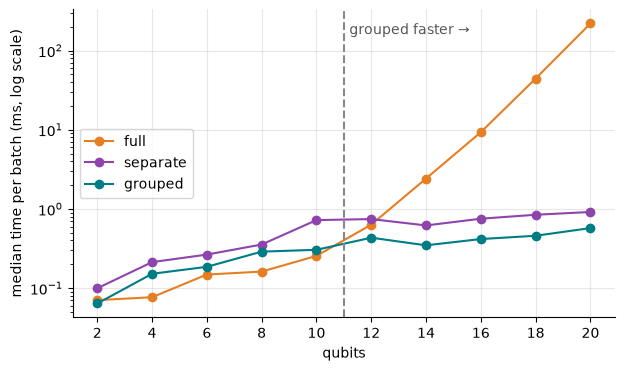

grouped beats full from 12 qubits on


| qubits | full (ms) | separate (ms) | grouped (ms) | auto picks | auto regret |
|---|---|---|---|---|---|
| 2 | 0.0706 | 0.0997 | 0.0640 | full | 1.33 |
| 4 | 0.0768 | 0.213 | 0.152 | grouped | 1.98 |
| 6 | 0.149 | 0.265 | 0.186 | grouped | 1.28 |
| 8 | 0.162 | 0.356 | 0.289 | grouped | 2.37 |
| 10 | 0.255 | 0.723 | 0.305 | grouped | 1.11 |
| 12 | 0.634 | 0.745 | 0.434 | grouped | 0.803 |
| 14 | 2.42 | 0.619 | 0.347 | grouped | 1.27 |
| 16 | 9.32 | 0.753 | 0.417 | grouped | 1.40 |
| 18 | 44.4 | 0.845 | 0.459 | grouped | 1.24 |
| 20 | 220 | 0.916 | 0.574 | grouped | 1.42 |

In [4]:
sweep = []
for pairs in range(1, 11):
    _, batch = pairs_program(pairs)
    times = {
        s: timed(lambda s=s: plan_all(batch, strategy=s).collect(), repeats=3)[1]
        for s in ("full", "separate", "grouped", "auto")
    }
    sweep.append((2 * pairs, times, plan_all(batch).explain()["selected_candidate"]))

fig, ax = plt.subplots(figsize=(7, 4))
for strategy in ("full", "separate", "grouped"):
    ax.plot([q for q, _, _ in sweep], [t[strategy] for _, t, _ in sweep],
            marker="o", color=COLORS[strategy], label=strategy)
faster = [t["grouped"] < t["full"] for _, t, _ in sweep]
crossover = next((sweep[i][0] for i in range(len(sweep)) if all(faster[i:])), None)
if crossover:
    ax.axvline(crossover - 1, color="#888888", linestyle="--")
    ax.text(crossover - 0.8, 0.92, "grouped faster →", transform=ax.get_xaxis_transform(), color="#555555")
ax.set_yscale("log")
ax.set_xticks([q for q, _, _ in sweep])
ax.set_xlabel("qubits")
ax.set_ylabel("median time per batch (ms, log scale)")
ax.legend(loc="center left")
tidy(ax)
plt.show()

if crossover:
    print(f"grouped beats full from {crossover} qubits on")
else:
    print("full stayed faster over this range")
table(
    [(q, t["full"], t["separate"], t["grouped"], auto, t["auto"] / min(t["full"], t["separate"], t["grouped"]))
     for q, t, auto in sweep],
    ["qubits", "full (ms)", "separate (ms)", "grouped (ms)", "auto picks", "auto regret"],
)

## When deciding costs more than simulating

Planning is not free, and on a small circuit it can cost more than the simulation it
is meant to shrink. Analysis can save at most the dense execution it replaces, so
before building any cone candidate LazyQC compares two predictions: the dense
execution time and the analysis time. If the dense plan is cheaper than the analysis
alone, no cone plan could repay it, and `auto` keeps the dense plan without analysing.

Hamiltonian averaging on a small circuit is the classic case: a 6-qubit, four-layer
circuit and 64 overlapping two-qubit Pauli terms, the shape of a small-molecule energy
evaluation.

In [5]:
small = Program(6)
for layer in range(4):
    for q in range(6):
        small = small.ry(q, 0.1 + 0.07 * (6 * layer + q))
    for q in range(layer % 2, 5, 2):
        small = small.cx(q, q + 1)
terms = [small.expectation({i % 6: "XYZ"[i % 3], (i + 1) % 6: "XYZ"[(i + 2) % 3]}) for i in range(64)]

budget = plan_all(terms).explain()["analysis_budget"]
print(f"predicted dense execution {budget['predicted_dense_ns'] / 1e3:.0f} µs, "
      f"predicted analysis {budget['predicted_analysis_ns'] / 1e3:.0f} µs, analysis skipped: {budget['skipped']}")

runs = {
    "auto (with the budget, the default)": lambda: plan_all(terms).collect(),
    'auto with analysis="always"': lambda: plan_all(terms, analysis="always").collect(),
    "forced full": lambda: plan_all(terms, strategy="full").collect(),
}
times = compare(runs, rounds=21)  # interleaved, so drift hits every plan equally
best = min(times.values())
table([(name, ms, ms / best) for name, ms in times.items()], ["plan", "median time (ms)", "regret vs best"])

predicted dense execution 104 µs, predicted analysis 484 µs, analysis skipped: True


| plan | median time (ms) | regret vs best |
|---|---|---|
| auto (with the budget, the default) | 0.592 | 1.00 |
| auto with analysis="always" | 0.853 | 1.44 |
| forced full | 0.600 | 1.01 |

Both `auto` variants end up with the dense plan, but the budgeted one gets there
without paying for an analysis that could never pay off. Skipping the analysis does
not make deciding free: what remains is the small gap between `auto` and the forced
dense plan. The rule is deliberately conservative. It only skips analysis that could not pay
even if every cone were free, so on most batches it never triggers.

## What to take away

- Cones avoid simulating qubits that cannot matter; sharing avoids repeating the same
  simulation. Grouping combines both.
- The crossover depends on the workload and the machine, not on a universal constant.
  For this family the full state's exponential growth wins out quickly; a circuit
  whose cones span the whole register would never cross over at all.
- `auto` decides from the batch alone, before running anything, so it is judged by
  its regret against the best forced plan. At the smallest sizes it may pick grouped
  when full is as fast, which costs a fraction of a millisecond; once the full state
  grows, its choice is the one that matters.
- Deciding has a cost too. The analysis budget skips the analysis when it could not
  pay even if every cone were free.

## Try it yourself

Inside `pairs_program`, link neighbouring pairs with `program = program.cx(b, b + 1)`
(skipping the last pair) and rerun the sweep. The cones now grow along the chain.
How does that change the picture?